<a href="https://colab.research.google.com/github/costpetrides/Numerical-Methods-GFD/blob/main/Petrides/Solutions/Diffusion/FTCS_1D_p.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# <span style="color:rgb(213,80,0)">Μέθοδος FTCS 1D</span>

##  Άσκηση 1.

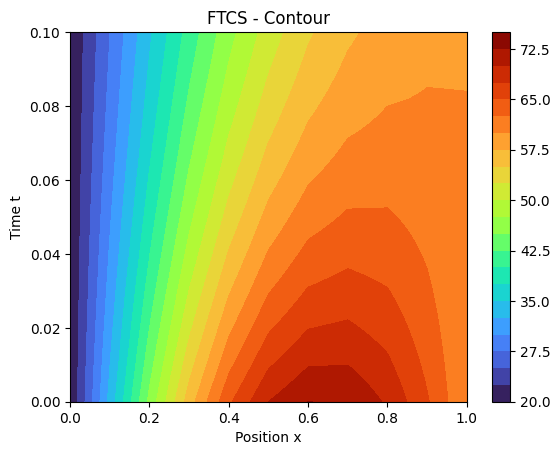

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.close("all")

L = 1
T = 0.1
h = 0.1
k = 0.002

x = np.arange(0,L+h/2,h)
t = np.arange(0,T+k/2,k)

Nx = len(x)
Nt = len(t)

r = k/h**2

assert r <= 0.5, 'FTCS is unstable'

u = np.zeros((Nx,Nt))

# Initial condition
u[:,0] = 20 + 40*x + 30*np.sin(np.pi*x)

# Dirichlet boundary conditions
u[0,:] = 20
u[-1,:] = 60

# FTCS method
i = np.arange(1,Nx-1)

for j in range(Nt-1):
    u[i,j+1] = u[i,j] + r*(
        u[i-1,j] - 2*u[i,j] + u[i+1,j])

# Contour
plt.figure()
plt.contourf(x,t,u.T,25,cmap="turbo")
plt.colorbar()
plt.xlabel('Position x')
plt.ylabel('Time t')
plt.title('FTCS - Contour')
plt.axis("tight")
plt.show()

## Άσκηση 2.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.close("all")

L = 1
T = 0.1
h = 0.05
k = 0.001

x = np.arange(0,L+h/2,h)
t = np.arange(0,T+k/2,k)

Nx = len(x)
Nt = len(t)

r = k/h**2

assert r <= 0.5, 'FTCS is unstable'

u = np.zeros((Nx,Nt))

# Initial condition
u[:,0] = 20 + 40*x + 30*np.sin(2*np.pi*x) \
         + 20*x*(1-x)

# Dirichlet boundary conditions
u[0,:] = 20 + 10*np.sin(20*np.pi*t)
u[-1,:] = 60 + 100*t

# FTCS method
i = np.arange(1,Nx-1)

for j in range(Nt-1):
    u[i,j+1] = u[i,j] + r*(
        u[i-1,j] - 2*u[i,j] + u[i+1,j])

# Value at x = 0.35, t = 0.05
ix = round(0.35/h)
jt = round(0.05/k)

print(f"u(0.35,0.05) = {u[ix,jt]:.6f}")

u(0.35,0.05) = 42.147594


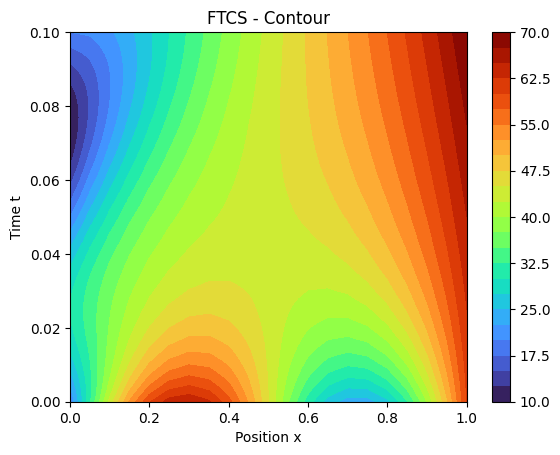

In [3]:
# Contour
plt.figure()
plt.contourf(x,t,u.T,25,cmap="turbo")
plt.colorbar()
plt.xlabel('Position x')
plt.ylabel('Time t')
plt.title('FTCS - Contour')
plt.axis("tight")
plt.show()

## Άσκηση 3.

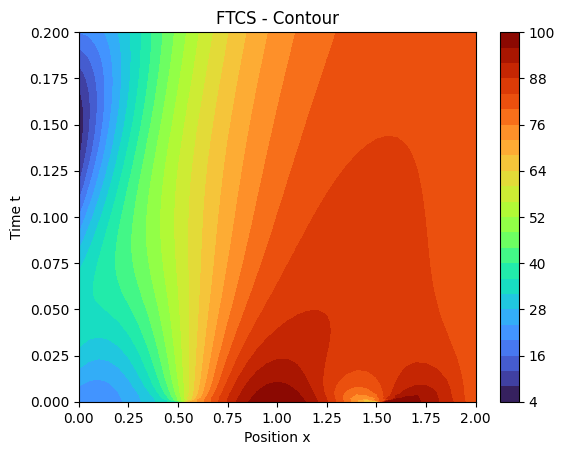

In [4]:
import numpy as np
import matplotlib.pyplot as plt

plt.close("all")

L = 2
T = 0.2
h = 0.05
k = 0.001

x = np.arange(0,L+h/2,h)
t = np.arange(0,T+k/2,k)

Nx = len(x)
Nt = len(t)

r = k/h**2

assert r <= 0.5, 'FTCS is unstable'

u = np.zeros((Nx,Nt))

# Initial condition
u[x <= 0.5,0] = 20 + 80*x[x <= 0.5]**2

u[(x > 0.5) & (x <= 1.5),0] = \
    60 + 40*np.sin(np.pi*(x[(x > 0.5) & (x <= 1.5)]-0.5))

u[x > 1.5,0] = \
    100 - 80*(x[x > 1.5]-1.5)**2

# Dirichlet boundary conditions
u[0,:] = 20 + 15*np.sin(10*np.pi*t)
u[-1,:] = 80 + 20*t

# FTCS method
i = np.arange(1,Nx-1)

for j in range(Nt-1):
    u[i,j+1] = u[i,j] + r*(
        u[i-1,j] - 2*u[i,j] + u[i+1,j])

# Contour
plt.figure()
plt.contourf(x,t,u.T,25,cmap="turbo")
plt.colorbar()
plt.xlabel('Position x')
plt.ylabel('Time t')
plt.title('FTCS - Contour')
plt.axis("tight")
plt.show()

In [5]:
# Maximum temperature
umax = np.max(u)
ix,jt = np.argwhere(u.T == umax)[0][::-1]

print(f"Max = {umax:.2f} at x = {x[ix]:.2f}, t = {t[jt]:.3f}")

Max = 100.00 at x = 1.00, t = 0.000



## Άσκηση 4.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

plt.close("all")

L = 2
T = 0.3
h = 0.05
k = 0.001

x = np.arange(0,L+h/2,h)
t = np.arange(0,T+k/2,k)

Nx = len(x)
Nt = len(t)

r = k/h**2

assert r <= 0.5, 'FTCS is unstable'

u = np.zeros((Nx,Nt))

# Initial condition
u[:,0] = 50

# Left Dirichlet boundary
a = t <= 0.1
b = t > 0.1

u[0,a] = 50 + 20*np.sin(5*np.pi*t[a])
u[0,b] = 70 - 100*(t[b]-0.1)

# Right Dirichlet boundary
a = t <= 0.15
b = t > 0.15

u[-1,a] = 50 + 100*t[a]
u[-1,b] = 65 - 200*(t[b]-0.15)**2

# FTCS method
i = np.arange(1,Nx-1)

for j in range(Nt-1):
    u[i,j+1] = u[i,j] + r*(
        u[i-1,j] - 2*u[i,j] + u[i+1,j])

# Maximum temperature
umax = np.max(u)
ix,jt = np.argwhere(u.T == umax)[0][::-1]

print(f"Max = {umax:.2f} at x = {x[ix]:.2f}, t = {t[jt]:.3f}")

Max = 70.00 at x = 0.00, t = 0.100


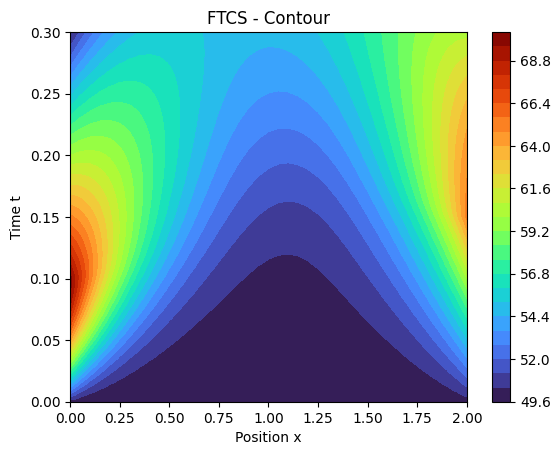

In [7]:
# Contour
plt.figure()
plt.contourf(x,t,u.T,25,cmap="turbo")
plt.colorbar()
plt.xlabel('Position x')
plt.ylabel('Time t')
plt.title('FTCS - Contour')
plt.axis("tight")
plt.show()

## Άσκηση 5.

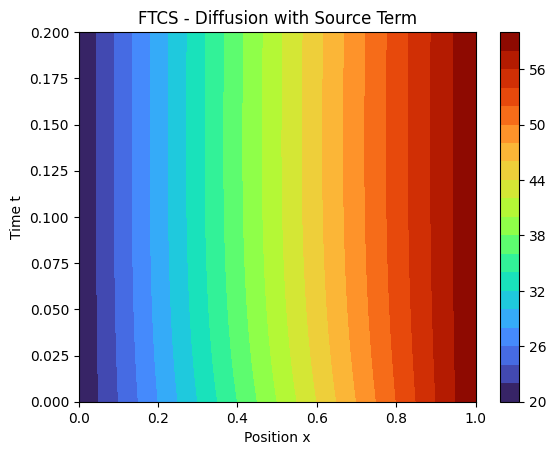

In [8]:
import numpy as np
import matplotlib.pyplot as plt

plt.close("all")

L = 1
T = 0.2
h = 0.05
k = 0.001

x = np.arange(0,L+h/2,h)
t = np.arange(0,T+k/2,k)

Nx = len(x)
Nt = len(t)

r = k/h**2

assert r <= 0.5, 'FTCS is unstable'

u = np.zeros((Nx,Nt))

# Initial condition
u[:,0] = 20 + 40*x

# Dirichlet boundary conditions
u[0,:] = 20
u[-1,:] = 60

# FTCS method with source term
i = np.arange(1,Nx-1)

for j in range(Nt-1):
    S = 30*np.exp(-5*t[j])*np.sin(np.pi*x[i])

    u[i,j+1] = u[i,j] + r*(
        u[i-1,j] - 2*u[i,j] + u[i+1,j]) \
        + k*S

# Contour
plt.figure()
plt.contourf(x,t,u.T,25,cmap="turbo")
plt.colorbar()
plt.xlabel('Position x')
plt.ylabel('Time t')
plt.title('FTCS - Diffusion with Source Term')
plt.axis("tight")
plt.show()

## Άσκηση 6.

Ο όρος πηγής υπολογίζεται από τη γνωστή τιμή $u_i^j$


στο προηγούμενο χρονικό επίπεδο. Έτσι, η μέθοδος


παραμένει ρητή (Explicit FTCS).


$$u_i^{j+1} =u_i^j +r(u_{i-1}^j -2u_i^j +u_{i+1}^j )+3ku_i^j$$

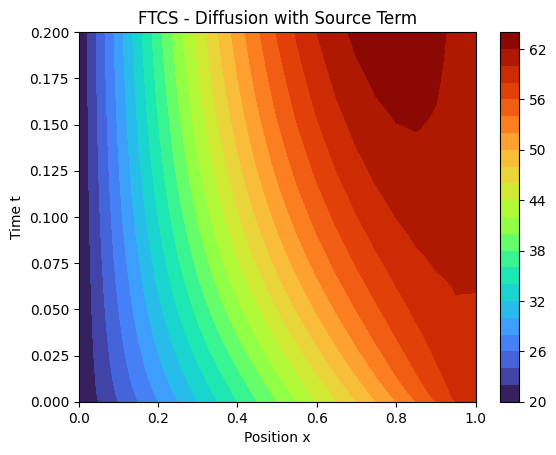

In [9]:
import numpy as np
import matplotlib.pyplot as plt

plt.close("all")

L = 1
T = 0.2
h = 0.05
k = 0.001

x = np.arange(0,L+h/2,h)
t = np.arange(0,T+k/2,k)

Nx = len(x)
Nt = len(t)

r = k/h**2

assert r <= 0.5, 'FTCS is unstable'

u = np.zeros((Nx,Nt))

# Initial condition
u[:,0] = 20 + 40*x

# Dirichlet boundary conditions
u[0,:] = 20
u[-1,:] = 60

# FTCS method with source term
i = np.arange(1,Nx-1)

for j in range(Nt-1):
    u[i,j+1] = u[i,j] + r*(
        u[i-1,j] - 2*u[i,j] + u[i+1,j]) \
        + 3*k*u[i,j]

# Contour
plt.figure()
plt.contourf(x,t,u.T,25,cmap="turbo")
plt.colorbar()
plt.xlabel('Position x')
plt.ylabel('Time t')
plt.title('FTCS - Diffusion with Source Term')
plt.axis("tight")
plt.show()

## Άσκηση 7.

Εφαρμόζουμε τη μέθοδο FTCS:


 $u_i^{j+1} =u_i^j +r(u_{i-1}^j -2u_i^j +u_{i+1}^j )$      όπου $r=\frac{k}{h^2 }$.


$$u_1^{j+1} =u_1^j +r(u_0^j -2u_1^j +u_2^j )$$

Δεν γνωρίζουμε το $u_o$ επομένως πρέπει να το υπολογίσουμε μέσο των συνοριακών!


Εφαρμόζουμε Centered Difference στην οριακή συνθήκη:


$$\frac{u_2^j -u_0^j }{2h}=u_1^j$$

Λύνουμε ως προς το εικονικό σημείο:


$$u_0^j =u_2^j -2hu_1^j$$

Αντικαθιστούμε στον τύπο FTCS:


$$u_1^{j+1} =u_1^j +r(u_2^j -2hu_1^j -2u_1^j +u_2^j )$$

Ομαδοποιώντας τους όρους, προκύπτει:


$$u_1^{j+1} =u_1^j +2r[u_2^j -(1+h)u_1^j ]$$

Εφαρμόζουμε Centered Difference στην οριακή συνθήκη:


$$\frac{u_{N_x +1}^j -u_{N_x -1}^j }{2h}=-u_{N_x }^j$$

Λύνουμε ως προς το εικονικό σημείο:


$$u_{N_x +1}^j =u_{N_x -1}^j -2hu_{N_x }^j$$

Αντικαθιστούμε στον τύπο FTCS:


$$u_{N_x }^{j+1} =u_{N_x }^j +r(u_{N_x -1}^j -2u_{N_x }^j +u_{N_x -1}^j -2hu_{N_x }^j )$$

Ομαδοποιώντας τους όρους, προκύπτει:


$$u_{N_x }^{j+1} =u_{N_x }^j +2r[u_{N_x -1}^j -(1+h)u_{N_x }^j ]$$

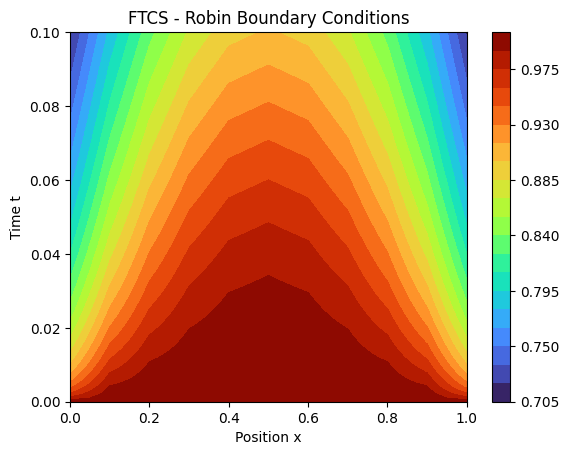

In [10]:
import numpy as np
import matplotlib.pyplot as plt

plt.close("all")

L = 1
T = 0.1
h = 0.1
k = 0.001

x = np.arange(0,L+h/2,h)
t = np.arange(0,T+k/2,k)

Nx = len(x)
Nt = len(t)

r = k/h**2

assert r <= 1/(2*(1+h)), 'FTCS stability condition violated'

u = np.zeros((Nx,Nt))

# Initial condition
u[:,0] = 1

# FTCS method
i = np.arange(1,Nx-1)

for j in range(Nt-1):

    # Interior points
    u[i,j+1] = u[i,j] + r*(
        u[i-1,j] - 2*u[i,j] + u[i+1,j])

    # Left Robin boundary
    u[0,j+1] = u[0,j] + 2*r*(
        u[1,j] - (1+h)*u[0,j])

    # Right Robin boundary
    u[-1,j+1] = u[-1,j] + 2*r*(
        u[-2,j] - (1+h)*u[-1,j])

# Contour
plt.figure()
plt.contourf(x,t,u.T,25,cmap="turbo")
plt.colorbar()
plt.xlabel('Position x')
plt.ylabel('Time t')
plt.title('FTCS - Robin Boundary Conditions')
plt.axis("tight")
plt.show()

## Άσκηση 8.

Στα εσωτερικά σημεία εφαρμόζουμε τη μέθοδο FTCS:


$$u_i^{j+1} =u_i^j +r(u_{i-1}^j -2u_i^j +u_{i+1}^j )$$

όπου $r=\frac{k}{h^2 }$


Εφαρμόζουμε Centered Difference στην οριακή συνθήκη:


$$\frac{u_2^j -u_0^j }{2h}=10+5\cos \left(\frac{\pi t_j }{T}\right)$$

Λύνοντας ως προς το εικονικό σημείο:


$$u_0^j =u_2^j -2h\left(10+5\cos \frac{\pi t_j }{T}\right)$$

Αντικαθιστούμε στον τύπο FTCS:


$$u_1^{j+1} =u_1^j +r(u_0^j -2u_1^j +u_2^j )$$

$$=u_1^j +r\left\lbrack 2u_2^j -2u_1^j -2h\left(10+5\cos \frac{\pi t_j }{T}\right)\right\rbrack$$

Ομαδοποιώντας τους όρους, προκύπτει:


$$u_1^{j+1} =u_1^j +2r\left\lbrack u_2^j -u_1^j -h\left(10+5\cos \frac{\pi t_j }{T}\right)\right\rbrack$$

Εφαρμόζουμε Centered Difference στην οριακή συνθήκη:


$$\frac{u_{N_x +1}^j -u_{N_x -1}^j }{2h}=10-5\sin \left(\frac{\pi t_j }{T}\right)$$

Λύνοντας ως προς το εικονικό σημείο:


$$u_{N_x +1}^j =u_{N_x -1}^j +2h\left(10-5\sin \frac{\pi t_j }{T}\right)$$

Αντικαθιστούμε στον τύπο FTCS:


$$u_{N_x }^{j+1} =u_{N_x }^j +r(u_{N_x -1}^j -2u_{N_x }^j +u_{N_x +1}^j )$$

$$=u_{N_x }^j +r\left\lbrack 2u_{N_x -1}^j -2u_{N_x }^j +2h\left(10-5\sin \frac{\pi t_j }{T}\right)\right\rbrack$$

Ομαδοποιώντας τους όρους, προκύπτει:


$$u_{N_x }^{j+1} =u_{N_x }^j +2r\left\lbrack u_{N_x -1}^j -u_{N_x }^j +h\left(10-5\sin \frac{\pi t_j }{T}\right)\right\rbrack$$

In [11]:
import numpy as np
import matplotlib.pyplot as plt

plt.close("all")

L = 1
T = 0.2
h = 0.05
k = 0.001

x = np.arange(0,L+h/2,h)
t = np.arange(0,T+k/2,k)

Nx = len(x)
Nt = len(t)

r = k/h**2

assert r <= 0.5, 'FTCS is unstable'

u = np.zeros((Nx,Nt))

# Initial condition
u[:,0] = 20 + 10*x + 5*np.sin(np.pi*x)

# FTCS method
i = np.arange(1,Nx-1)

for j in range(Nt-1):

    # Interior points
    u[i,j+1] = u[i,j] + r*(
        u[i-1,j] - 2*u[i,j] + u[i+1,j])

    # Left Neumann boundary
    u[0,j+1] = u[0,j] + 2*r*(
        u[1,j] - u[0,j] \
        - h*(10 + 5*np.cos(np.pi*t[j]/T)))

    # Right Neumann boundary
    u[-1,j+1] = u[-1,j] + 2*r*(
        u[-2,j] - u[-1,j] \
        + h*(10 - 5*np.sin(np.pi*t[j]/T)))

# Value at x = 0.5, t = 0.1
ix = round(0.5/h)
jt = round(0.1/k)

print(f"u(0.5,0.1) = {u[ix,jt]:.6f}")

u(0.5,0.1) = 27.835062


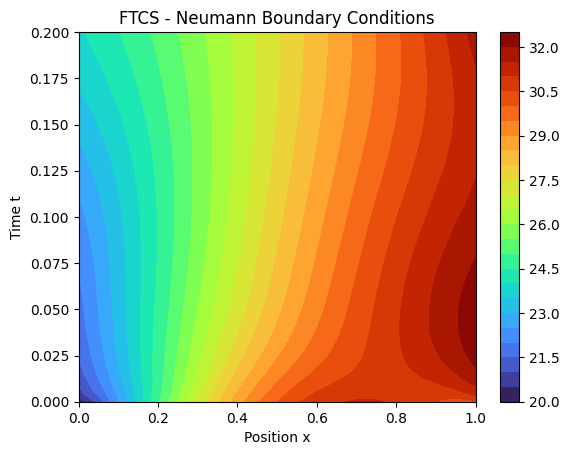

In [12]:
# Contour
plt.figure()
plt.contourf(x,t,u.T,25,cmap="turbo")
plt.colorbar()
plt.xlabel('Position x')
plt.ylabel('Time t')
plt.title('FTCS - Neumann Boundary Conditions')
plt.axis("tight")
plt.show()

## Άσκηση 9.

Στα εσωτερικά σημεία εφαρμόζουμε τη μέθοδο FTCS:


$$u_i^{j+1} =u_i^j +r(u_{i-1}^j -2u_i^j +u_{i+1}^j )$$

Εφαρμόζουμε Forward Difference στην οριακή συνθήκη:


$$\begin{array}{l} \frac{u_2^{j+1} -u_1^{j+1} }{h}=4+6{\left(\frac{t_{j+1} }{T}\right)}^2 ewline \end{array}$$

Πολλαπλασιάζουμε με h:


$$\begin{array}{l} u_2^{j+1} -u_1^{j+1} =h\left\lbrack 4+6{\left(\frac{t_{j+1} }{T}\right)}^2 \right\rbrack ewline \end{array}$$

Λύνοντας ως προς την τιμή στο αριστερό άκρο, προκύπτει:


$$\begin{array}{l} u_1^{j+1} =u_2^{j+1} -h\left\lbrack 4+6{\left(\frac{t_{j+1} }{T}\right)}^2 \right\rbrack ewline \end{array}$$

Εφαρμόζουμε Backward Difference στην οριακή συνθήκη:


$$\begin{array}{l} \frac{u_{N_x }^{j+1} -u_{N_x -1}^{j+1} }{h}=-3e^{-t_{j+1} /T} ewline \end{array}$$

Πολλαπλασιάζουμε με h:


$$\begin{array}{l} u_{N_x }^{j+1} -u_{N_x -1}^{j+1} =-3he^{-t_{j+1} /T} ewline \end{array}$$

Λύνοντας ως προς την τιμή στο δεξί άκρο, προκύπτει:


$$\begin{array}{l} u_{N_x }^{j+1} =u_{N_x -1}^{j+1} -3he^{-t_{j+1} /T} ewline \end{array}$$

In [13]:
import numpy as np
import matplotlib.pyplot as plt

plt.close("all")

L = 1
T = 0.2
h = 0.05
k = 0.001

x = np.arange(0,L+h/2,h)
t = np.arange(0,T+k/2,k)

Nx = len(x)
Nt = len(t)

r = k/h**2

assert r <= 0.5, 'FTCS is unstable'

u = np.zeros((Nx,Nt))

# Initial condition
u[:,0] = 20 + 4*x - 3.5*x**2 + 2*np.sin(np.pi*x)**2

# FTCS method
i = np.arange(1,Nx-1)

for j in range(Nt-1):

    # Interior points
    u[i,j+1] = u[i,j] + r*(
        u[i-1,j] - 2*u[i,j] + u[i+1,j])

    # Forward Difference - Left boundary
    u[0,j+1] = u[1,j+1] \
        - h*(4 + 6*(t[j+1]/T)**2)

    # Backward Difference - Right boundary
    u[-1,j+1] = u[-2,j+1] \
        - 3*h*np.exp(-t[j+1]/T)

# Value at x = 0.5, t = 0.1
ix = round(0.5/h)
jt = round(0.1/k)

print(f"u(0.5,0.1) = {u[ix,jt]:.6f}")

u(0.5,0.1) = 21.478191


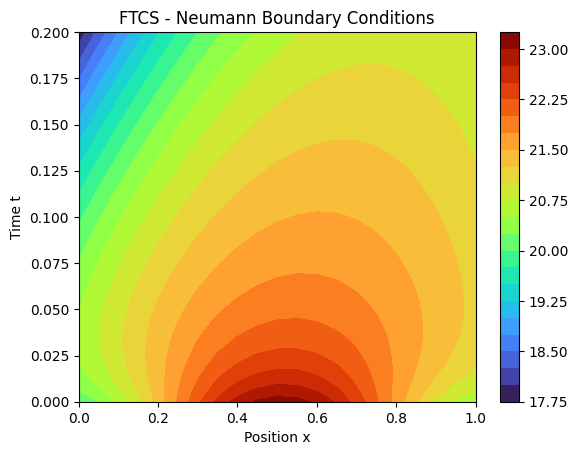

In [14]:
# Contour
plt.figure()
plt.contourf(x,t,u.T,25,cmap="turbo")
plt.colorbar()
plt.xlabel('Position x')
plt.ylabel('Time t')
plt.title('FTCS - Neumann Boundary Conditions')
plt.axis("tight")
plt.show()